In [1]:
# Notebook deployment
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
DB_FILE = PROJECT_ROOT / "data" / "processed" / "catastrophes.db"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

FIRST_YEAR, LAST_YEAR = 1967, 2026
SOURCE_NOTE = "Source: ICA Historical Normalised Catastrophe List (Sep 2026); ABS CPI via RBA G1."

conn = sqlite3.connect(DB_FILE)

# One consistent chart style for the whole notebook
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "font.size": 10,
})
COLOURS = {"original": "#adb5bd", "cpi_adjusted": "#4dabf7", "normalised": "#1c3d5a"}

### Question 1: How much does the lost increase?

In [2]:
# Take data by SQL
annual = pd.read_sql(
    """
    SELECT year,
           SUM(original_loss)          AS original,
           SUM(cpi_adjusted_loss_2022) AS cpi_adjusted,
           SUM(normalised_loss_2022)   AS normalised
    FROM events
    WHERE has_loss = 1
    GROUP BY year
    """,
    conn,
).set_index("year")

# Years with no catastrophe must count as zero loss, not be dropped
annual = annual.reindex(range(FIRST_YEAR, LAST_YEAR + 1), fill_value=0)

aal_by_decade = annual.groupby(annual.index // 10 * 10).mean() / 1e9  # A$ billion
aal_by_decade.round(2)

,original,cpi_adjusted,normalised
year,,,
1960,0.04,0.57,5.72
1970,0.07,0.64,2.84
1980,0.19,0.53,2.24
1990,0.38,0.74,2.36
2000,0.64,0.94,1.62
2010,2.31,2.78,3.60
2020,3.48,3.45,3.62


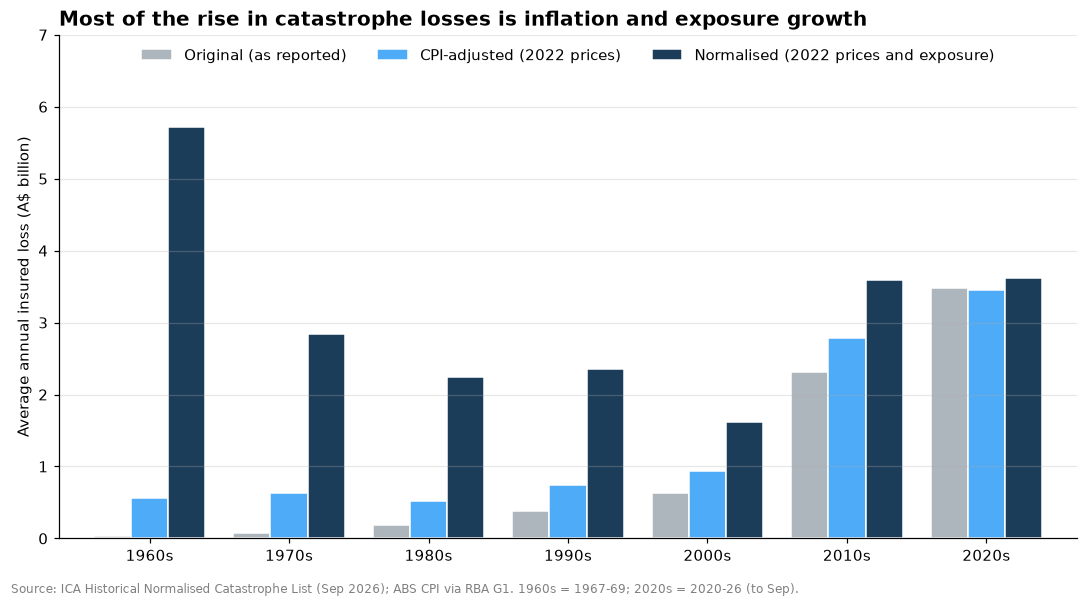

In [3]:
# Graphical representation of the data
fig, ax = plt.subplots(figsize=(10, 5.5))
aal_by_decade.plot.bar(
    ax=ax,
    color=[COLOURS[c] for c in aal_by_decade.columns],
    width=0.8,
    edgecolor="white",
)
ax.set_xticklabels([f"{d}s" for d in aal_by_decade.index], rotation=0)
ax.set_xlabel("")
ax.set_ylabel("Average annual insured loss (A$ billion)")
ax.set_title("Most of the rise in catastrophe losses is inflation and exposure growth", loc="left")
ax.legend(
    ["Original (as reported)", "CPI-adjusted (2022 prices)", "Normalised (2022 prices and exposure)"],
    frameon=False, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.0),
)
ax.set_ylim(0, 7)
ax.grid(axis="y", alpha=0.3)
fig.text(0.01, 0.01, SOURCE_NOTE + " 1960s = 1967-69; 2020s = 2020-26 (to Sep).",
         fontsize=8, color="grey")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG_DIR / "01_aal_by_decade.png", dpi=150)
plt.show()

### Insight 1: inflation and exposure growth explain most of the rise in losses

**Reported catastrophe losses have grown about 50-fold since the 1970s, but once
inflation and exposure growth are removed, the increase is much smaller.**

| Measure (average annual loss) | 1970s | 2020s | Change |
|---|---|---|---|
| Original (as reported) | $0.07bn | $3.48bn | ~50× |
| CPI-adjusted (2022 prices) | $0.64bn | $3.45bn | ~5× |
| Normalised (2022 prices and exposure) | $2.84bn | $3.62bn | +27% |

- **Inflation** accounts for roughly a tenfold rise (original vs CPI-adjusted).
- **Exposure growth** (more and more valuable insured property) accounts for most of
  the rest (CPI-adjusted vs normalised).
- On a normalised basis, the 2010s and 2020s (about $3.6bn a year) are still
  **around 75% higher** than the 1980s–2000s average (about $2.1bn a year).

**Caveats**
- The **1960s** figure ($5.7bn) is based on only three years (1967–69) that include
  two of the costliest events on record (Cyclone Dinah and the 1967 Hobart bushfires).
  Averages over short periods are dominated by single large events.
- The 2020s cover 2020 to September 2026 only.
- ICA's normalisation is a model; it may not capture every change in exposure, and
  smaller events are more completely recorded in recent decades.

**So what:** comparing raw insured losses over time overstates the trend in
catastrophe risk. The higher normalised losses in recent decades suggest a possible
increase in hazard, which is tested more formally in Question 4.

### Questions 2: Which type of catastrophe caused the biggest lost?

In [4]:
# Take data by SQL
by_peril = pd.read_sql(
    """
    SELECT peril,
           COUNT(*)                         AS events,
           SUM(normalised_loss_2022) / 1e9  AS total_loss_bn,
           avg(normalised_loss_2022) / 1e9  AS avg_loss_bn,
           MAX(normalised_loss_2022) / 1e9  AS max_loss_bn
    FROM events
    WHERE has_loss = 1 AND normalised_loss_2022 > 0
    GROUP BY peril
    ORDER BY total_loss_bn DESC
    """,
    conn,
).set_index("peril")

by_peril["share"] = by_peril["total_loss_bn"] / by_peril["total_loss_bn"].sum()
by_peril.round(3)

,events,total_loss_bn,avg_loss_bn,max_loss_bn,share
peril,,,,,
Hail,36,39.035,1.084,8.846,0.231
Cyclone,73,38.650,0.529,7.397,0.229
Flood,64,35.566,0.556,6.376,0.210
Storm,106,28.089,0.265,3.395,0.166
Bushfire,47,20.450,0.435,4.104,0.121
Earthquake,12,7.258,0.605,6.542,0.043


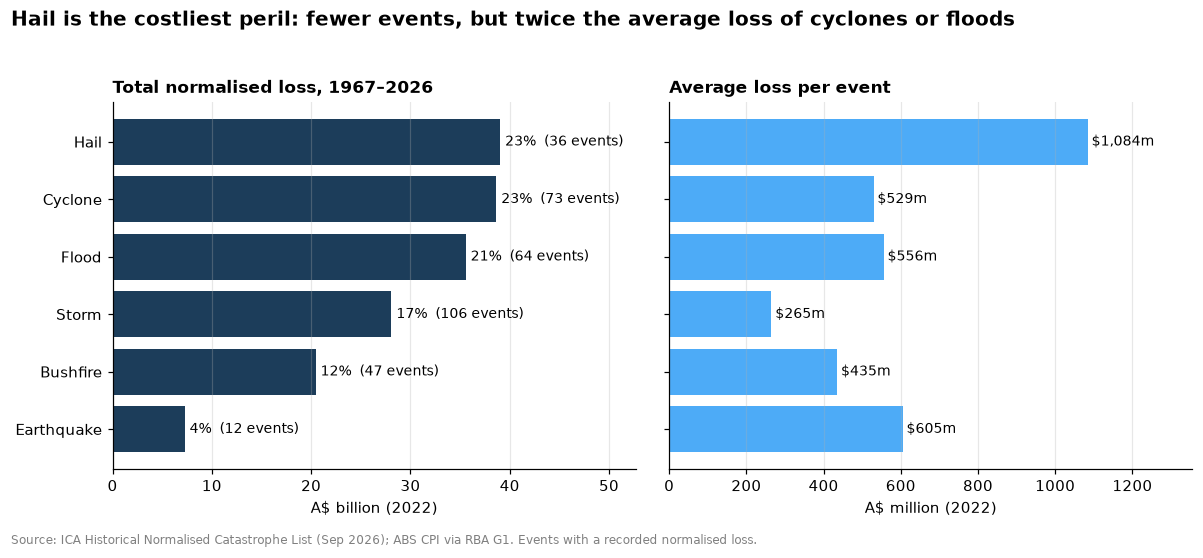

In [5]:
# Graphical representation of the data
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
order = by_peril.sort_values("total_loss_bn").index  # smallest first = drawn at the bottom

# Left panel: total loss, labelled with share and event count
ax1.barh(order, by_peril.loc[order, "total_loss_bn"], color=COLOURS["normalised"])
ax1.set_title("Total normalised loss, 1967–2026", loc="left", fontsize=11)
ax1.set_xlabel("A$ billion (2022)")
for peril in order:
    row = by_peril.loc[peril]
    ax1.text(row["total_loss_bn"] + 0.5, peril,
             f"{row['share']:.0%}  ({int(row['events'])} events)", va="center", fontsize=9)
ax1.set_xlim(0, by_peril["total_loss_bn"].max() * 1.35)

# Right panel: average loss per event
avg_m = by_peril.loc[order, "avg_loss_bn"] * 1000  # A$ million
ax2.barh(order, avg_m, color=COLOURS["cpi_adjusted"])
ax2.set_title("Average loss per event", loc="left", fontsize=11)
ax2.set_xlabel("A$ million (2022)")
for peril, value in avg_m.items():
    ax2.text(value + 10, peril, f"${value:,.0f}m", va="center", fontsize=9)
ax2.set_xlim(0, avg_m.max() * 1.25)

for ax in (ax1, ax2):
    ax.grid(axis="x", alpha=0.3)

fig.suptitle("Hail is the costliest peril: fewer events, but twice the average loss of cyclones or floods",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.text(0.01, 0.01, SOURCE_NOTE + " Events with a recorded normalised loss.", fontsize=8, color="grey")
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
fig.savefig(FIG_DIR / "02_loss_by_peril.png", dpi=150)
plt.show()

### Insight 2: hail is Australia's costliest natural peril

**Hail, cyclones and floods together account for about two-thirds (67%) of
normalised catastrophe losses since 1967, and hail ranks first despite having
far fewer events.**

- Hail caused **$39.0bn** in normalised losses from just **36 events**, about the
  same as cyclones ($38.7bn) from **73 events**.
- The difference is severity: the average hail event costs **$1.1bn**, roughly
  twice the average cyclone ($0.53bn) or flood ($0.56bn). One in three hail
  events (12 of 36) exceeded $1bn, compared with 9 of 73 cyclones.
- **Why:** major hailstorms have struck densely populated capital cities, such as
  Sydney (1999), Brisbane (1985) and Brisbane/Ipswich (2020), where homes and
  vehicles are highly concentrated. Most cyclones make landfall on sparsely
  populated northern coasts, with Cyclone Tracy (Darwin, 1974) a notable exception.

**Caveat:** the average earthquake loss ($605m) is not representative: $6.5bn of
the $7.3bn total comes from a single event, the 1989 Newcastle earthquake.

**So what:** hail risk is concentrated in metropolitan areas, so an insurer's
exposure to a single urban hailstorm can rival that of a major cyclone. This
matters for pricing, accumulation monitoring and reinsurance in capital cities.

### Question 3: Which state had the biggest lost, by which catastrophe?

In [6]:
# Loss matrix
STATE_ORDER = ["QLD", "NSW", "VIC", "WA", "SA", "TAS", "NT", "ACT", "Multi-state"]
PERIL_ORDER = ["Hail", "Cyclone", "Flood", "Storm", "Bushfire", "Earthquake"]

loss = pd.read_sql(
    """
    SELECT state_group, peril, SUM(normalised_loss_2022) / 1e9 AS loss_bn
    FROM events
    WHERE has_loss = 1 AND state_group <> 'Unknown'
    GROUP BY state_group, peril
    """,
    conn,
)

matrix = (
    loss.pivot(index="peril", columns="state_group", values="loss_bn")
    .reindex(index=PERIL_ORDER, columns=STATE_ORDER)
    .fillna(0)
)
matrix.round(1)

state_group,QLD,NSW,VIC,WA,SA,TAS,NT,ACT,Multi-state
peril,,,,,,,,,
Hail,12.0,19.9,1.8,0.0,0.4,0.0,0.0,0.0,5.0
Cyclone,24.5,0.0,0.0,3.4,0.0,0.0,7.4,0.0,3.3
Flood,13.8,5.3,1.8,0.1,0.5,0.1,0.4,0.0,13.4
Storm,4.4,9.3,5.6,2.5,0.1,0.2,0.0,0.0,5.3
Bushfire,0.0,1.7,8.8,0.5,0.6,4.3,0.0,1.3,3.2
Earthquake,0.0,6.9,0.1,0.2,0.0,0.0,0.0,0.0,0.0


In [7]:
# Number of events by state
pd.read_sql(
    """
    SELECT s.state,
           COUNT(*) AS events,
           SUM(CASE WHEN e.normalised_loss_2022 >= 1e9 THEN 1 ELSE 0 END) AS events_over_1bn
    FROM event_states AS s
    JOIN events AS e USING (event_id)
    WHERE e.has_loss = 1
    GROUP BY s.state
    ORDER BY events DESC
    """,
    conn,
)

,state,events,events_over_1bn
0,NSW,120,18
1,QLD,109,24
2,VIC,68,10
3,WA,53,1
4,SA,18,1
5,NT,11,1
6,ACT,11,6
7,TAS,9,1


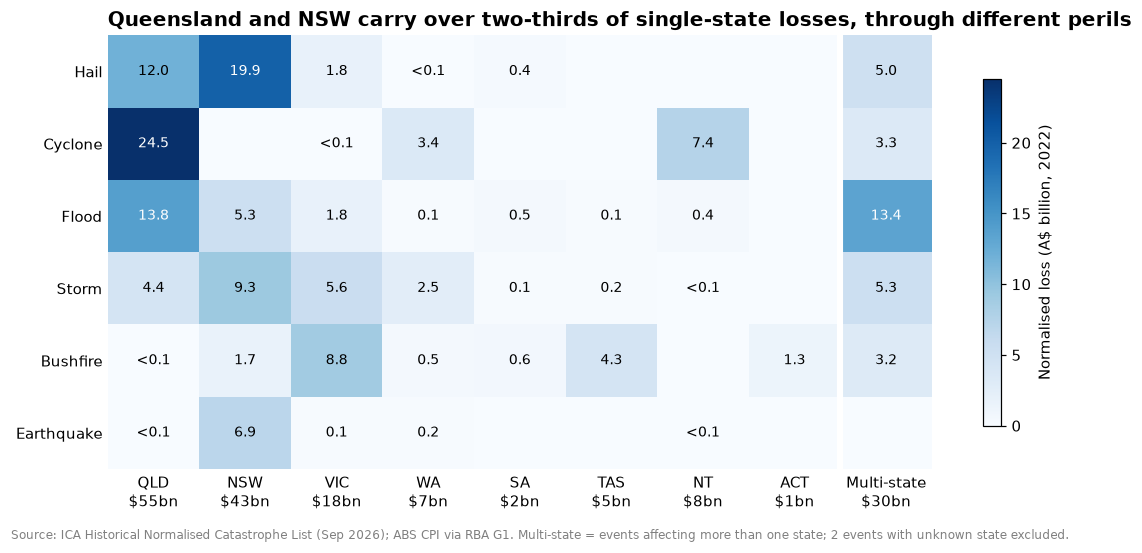

In [8]:
# Graphical representation of the data
fig, ax = plt.subplots(figsize=(10.5, 5))
im = ax.imshow(matrix.values, cmap="Blues", aspect="auto")

# Write the value in each cell; white text on dark cells, black on light cells
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        v = matrix.iat[i, j]
        if v > 0:
            ax.text(j, i, f"{v:.1f}" if v >= 0.05 else "<0.1", ha="center", va="center",
                    fontsize=9, color="white" if v > matrix.values.max() * 0.5 else "black")

totals = matrix.sum()
ax.set_xticks(range(len(STATE_ORDER)), [f"{s}\n${totals[s]:.0f}bn" for s in STATE_ORDER])
ax.set_yticks(range(len(PERIL_ORDER)), PERIL_ORDER)
ax.spines[:].set_visible(False)
ax.tick_params(length=0)
ax.axvline(len(STATE_ORDER) - 1.5, color="white", linewidth=4)  # separate Multi-state

fig.colorbar(im, ax=ax, label="Normalised loss (A$ billion, 2022)", shrink=0.8)
ax.set_title("Queensland and NSW carry over two-thirds of single-state losses, through different perils",
             loc="left")
fig.text(0.01, 0.01, SOURCE_NOTE + " Multi-state = events affecting more than one state; "
         "2 events with unknown state excluded.", fontsize=8, color="grey")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG_DIR / "03_loss_by_state_and_peril.png", dpi=150)
plt.show()

### Insight 3: Queensland and NSW dominate losses, but through different perils

**Queensland ($55bn) and NSW ($43bn) account for about 71% of single-state
catastrophe losses (58% including multi-state events), and each state's
losses are driven by a different peril.**

- **Queensland:** cyclones are the largest source ($24.5bn), followed by floods
  ($13.8bn) and hail ($12.0bn).
- **NSW:** hail is the largest source ($19.9bn), driven by major Sydney
  hailstorms such as 1999. NSW records almost no cyclone losses.
- **Victoria and Tasmania:** bushfire is the leading peril ($8.8bn and $4.3bn),
  reflecting events such as the 1967 Hobart fires, Ash Wednesday (1983) and
  Black Saturday (2009).
- **Western Australia:** 53 loss events (fourth-highest) but only **$7bn** in
  losses, and just **one event above $1bn**. Most WA cyclone losses occur in the
  sparsely populated Pilbara and Kimberley, while Perth lies south of the main
  cyclone belt.
- **Floods** are the largest component of multi-state losses ($13.4bn), likely
  because large rain systems (La Niña rainfall, ex-tropical cyclones, East Coast
  Lows) and river catchments such as the Murray–Darling span state borders.

**Caveat:** losses from multi-state events cannot be split between states, so
state totals understate exposure for states often hit by large multi-state
events (e.g. the 2022 south-east Queensland and northern NSW floods).

**So what:** catastrophe risk is concentrated on the east coast, and the key
peril differs by state, so pricing and reinsurance need to reflect regional
peril profiles rather than a single national view.

### Question 4: Did big catastrophes happen oftenly?

In [12]:
# Import statsmodel to run Poisson regression
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [13]:
# Count the number of large events each year where large is defined as a normalised loss of at least 100 million
FIRST_FULL_YEAR, LAST_FULL_YEAR = 1967, 2025  # 2026 is a partial year
THRESHOLD = 100e6  # A$100m normalised (2022)

events = pd.read_sql(
    "SELECT year, normalised_loss_2022 FROM events WHERE has_loss = 1",
    conn,
)


def annual_counts(events: pd.DataFrame, threshold: float) -> pd.DataFrame:
    """Number of events at or above the loss threshold in each full calendar year."""
    big = events[
        (events["normalised_loss_2022"] >= threshold)
        & events["year"].between(FIRST_FULL_YEAR, LAST_FULL_YEAR)
    ]
    return (
        big.groupby("year").size()
        .reindex(range(FIRST_FULL_YEAR, LAST_FULL_YEAR + 1), fill_value=0)
        .rename("events")
        .reset_index()
    )


counts = annual_counts(events, THRESHOLD)
print(f"{counts['events'].sum()} events, {counts['events'].mean():.2f} per year on average")

179 events, 3.03 per year on average


In [14]:
# Poisson regression model
def fit_poisson_trend(counts: pd.DataFrame):
    """Poisson GLM with log link: log(expected events) = b0 + b1 * year."""
    model = smf.glm("events ~ year", data=counts, family=sm.families.Poisson()).fit()
    beta = model.params["year"]
    ci_low, ci_high = model.conf_int().loc["year"]
    result = {
        "annual_change": np.exp(beta) - 1,
        "ci_low": np.exp(ci_low) - 1,
        "ci_high": np.exp(ci_high) - 1,
        "p_value": model.pvalues["year"],
        "dispersion": model.pearson_chi2 / model.df_resid,
    }
    return model, result


model, result = fit_poisson_trend(counts)
print(model.summary())
result

                 Generalized Linear Model Regression Results                  
Dep. Variable:                 events   No. Observations:                   59
Model:                            GLM   Df Residuals:                       57
Model Family:                 Poisson   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -114.15
Date:                Mon, 02 Nov 2026   Deviance:                       64.901
Time:                        23:32:06   Pearson chi2:                     57.9
No. Iterations:                     4   Pseudo R-squ. (CS):            0.03112
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -10.8787      8.796     -1.237      0.2

{'annual_change': np.float64(0.006021717341722077),
 'ci_low': np.float64(-0.002622336438088735),
 'ci_high': np.float64(0.014740687242555062),
 'p_value': np.float64(0.17269891194072562),
 'dispersion': np.float64(1.0166405551016042)}

In [17]:
# Check sensitivity of the trend to the threshold for a "large" event
rows = []
for threshold in [100e6, 250e6, 500e6, 1e9]:
    c = annual_counts(events, threshold)
    _, r = fit_poisson_trend(c)
    rows.append({
        "threshold": f"${threshold / 1e6:,.0f}m",
        "events": c["events"].sum(),
        "per_year": c["events"].mean(),
        **r,
    })

sensitivity = pd.DataFrame(rows).set_index("threshold")
sensitivity.style.format({
    "per_year": "{:.2f}", "annual_change": "{:+.2%}", "ci_low": "{:+.2%}",
    "ci_high": "{:+.2%}", "p_value": "{:.3f}", "dispersion": "{:.2f}",
})

,events,per_year,annual_change,ci_low,ci_high,p_value,dispersion
threshold,,,,,,,
$100m,179,3.03,+0.60%,-0.26%,+1.47%,0.173,1.02
$250m,117,1.98,+1.10%,+0.01%,+2.19%,0.047,1.25
$500m,74,1.25,+1.33%,-0.04%,+2.72%,0.056,1.27
"$1,000m",43,0.73,+1.43%,-0.37%,+3.26%,0.119,1.39


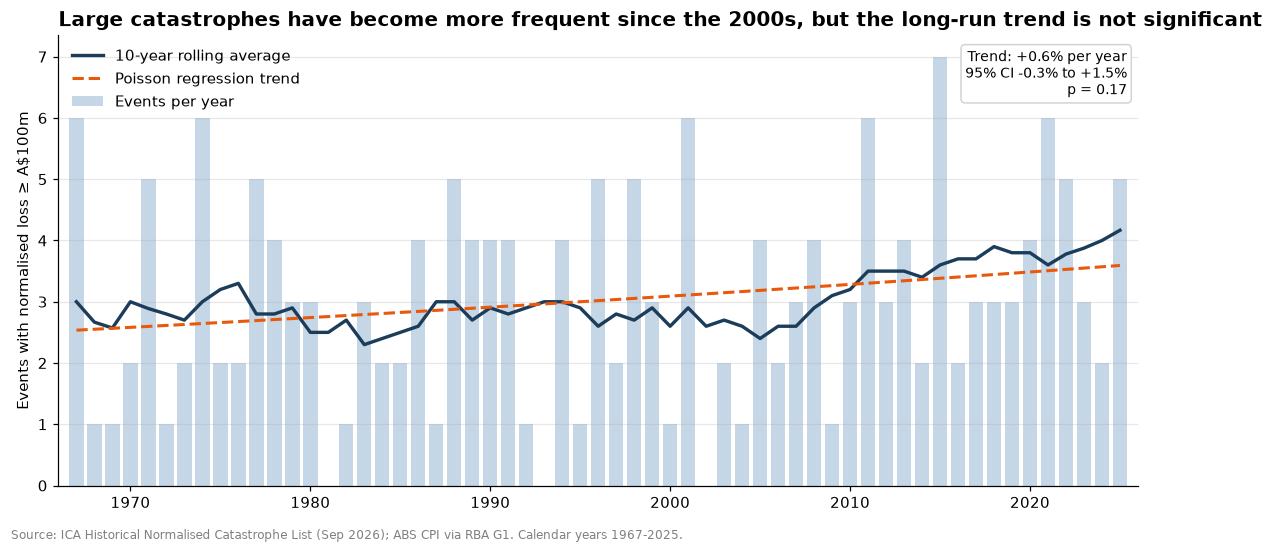

In [18]:
# Graphical representation of the data
counts["fitted"] = model.predict(counts)
counts["rolling_10y"] = counts["events"].rolling(10, center=True, min_periods=5).mean()

fig, ax = plt.subplots(figsize=(10.5, 5))
ax.bar(counts["year"], counts["events"], color="#c5d6e6", label="Events per year")
ax.plot(counts["year"], counts["rolling_10y"], color=COLOURS["normalised"], linewidth=2.2,
        label="10-year rolling average")
ax.plot(counts["year"], counts["fitted"], color="#e8590c", linestyle="--", linewidth=2,
        label="Poisson regression trend")
ax.set_ylabel("Events with normalised loss ≥ A$100m")
ax.set_title("Large catastrophes have become more frequent since the 2000s, "
             "but the long-run trend is not significant", loc="left")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", alpha=0.3)
ax.set_xlim(FIRST_FULL_YEAR - 1, LAST_FULL_YEAR + 1)

# Model result box in the top-right corner
ax.text(
    0.99, 0.97,
    f"Trend: {result['annual_change']:+.1%} per year\n"
    f"95% CI {result['ci_low']:+.1%} to {result['ci_high']:+.1%}\n"
    f"p = {result['p_value']:.2f}",
    transform=ax.transAxes, ha="right", va="top", fontsize=9,
    bbox=dict(boxstyle="round", facecolor="white", edgecolor="#ced4da"),
)
fig.text(0.01, 0.01, SOURCE_NOTE + " Calendar years 1967-2025.", fontsize=8, color="grey")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG_DIR / "04_large_event_frequency.png", dpi=150)
plt.show()

### Insight 4: large catastrophes are more frequent recently, but the long-run trend is uncertain

**Australia has experienced more large catastrophes since the late 2000s, but over
the full 1967–2025 record the evidence for a sustained upward trend in frequency
is weak.**

- Events with a normalised loss of at least **A$100m** averaged **2.4 to 3.2 per year**
  from the 1970s to the 2000s, rising to **3.6 per year in the 2010s** and
  **4.2 per year in 2020–2025**.
- A Poisson regression of annual counts on year estimates a trend of
  **+0.6% per year** (95% CI −0.3% to +1.5%, p = 0.17). The interval includes zero,
  so the long-run trend is **not statistically significant**.
- The direction is **consistent across thresholds**: estimates range from +0.6% to
  +1.4% per year for thresholds between A$100m and A$1bn, but only the A$250m
  threshold is borderline significant (p = 0.047).

| Threshold | Events | Per year | Annual trend | 95% CI | p-value |
|---|---|---|---|---|---|
| A$100m (main) | 179 | 3.03 | +0.6% | −0.3% to +1.5% | 0.17 |
| A$250m | 117 | 1.98 | +1.1% | +0.0% to +2.2% | 0.05 |
| A$500m | 74 | 1.25 | +1.3% | −0.0% to +2.7% | 0.06 |
| A$1bn | 43 | 0.73 | +1.4% | −0.4% to +3.3% | 0.12 |

**Caveats**
- A single log-linear trend is a simple model: the 10-year average is broadly flat
  until the late 2000s and then rises, a shape a straight-line trend cannot capture.
- At higher thresholds the counts are mildly **overdispersed** (dispersion
  1.25–1.39), so the Poisson p-values are somewhat optimistic; a negative binomial
  model would give wider intervals.
- 59 years is a short record for rare events, and years can cluster (for example
  the La Niña periods of 2010–12 and 2020–22). The data cannot separate natural
  climate variability from long-term climate change.
- The A$100m threshold was chosen before testing; the other thresholds are a
  sensitivity check, not alternatives to pick from.

**So what:** "not statistically significant" is not the same as "no change". The
recent increase is material for insurers, and with a short record, a real trend
could easily go undetected. Recent experience deserves extra weight in pricing and
capital planning, and the trend should be monitored as new years are added.
Natural next steps are a negative binomial model and a climate driver such as
the El Niño–Southern Oscillation (ENSO).

### Question 5: loss distribution

In [19]:
# Focus rate
import matplotlib.ticker as mticker
from scipy import optimize, stats

losses = pd.read_sql(
    """
    SELECT event_name, year, peril, normalised_loss_2022 AS loss
    FROM events
    WHERE has_loss = 1 AND normalised_loss_2022 > 0
    ORDER BY loss DESC
    """,
    conn,
)

# Cumulative share of total loss, events sorted from largest to smallest
share = losses["loss"].cumsum() / losses["loss"].sum()

print(f"{len(losses)} events")
print(f"Top 10 events: {share.iloc[9]:.0%} of total loss")
print(f"Events needed to reach 50% of total loss: {(share < 0.5).sum() + 1}")
losses.head(10).assign(loss_bn=lambda d: (d["loss"] / 1e9).round(2)).drop(columns="loss")

338 events
Top 10 events: 32% of total loss
Events needed to reach 50% of total loss: 23


,event_name,year,peril,loss_bn
0,Eastern Sydney Hailstorm,1999,Hail,8.85
1,Cyclone TRACEY,1974,Cyclone,7.40
2,Newcastle CDB Earthquake,1989,Earthquake,6.54
3,SE Queensland and NSW Floods,2022,Flood,6.38
4,Cyclone DINAH,1967,Cyclone,6.19
5,Brisbane Floods,1974,Flood,5.26
6,Bushfire,1967,Bushfire,4.10
7,Brisbane Hail Storm,1985,Hail,3.75
8,East Coast Low,2007,Storm,3.39
9,Cyclone ELAINE,1967,Cyclone,2.74


In [20]:
# Pareto, Lognormal, and Lgnormal truncated
N_YEARS = LAST_FULL_YEAR - FIRST_FULL_YEAR + 1  # 59 full years

large = losses.loc[
    (losses["loss"] >= THRESHOLD) & losses["year"].between(FIRST_FULL_YEAR, LAST_FULL_YEAR),
    "loss",
].to_numpy()
rate = len(large) / N_YEARS  # large events per year (frequency)

# Model 1 - Pareto: maximum likelihood estimate has a closed form
alpha = len(large) / np.log(large / THRESHOLD).sum()

# Model 2 - Lognormal ignoring the threshold: mean and sd of log losses
log_x, log_u = np.log(large), np.log(THRESHOLD)
mu_naive, sigma_naive = log_x.mean(), log_x.std(ddof=1)


# Model 3 - Lognormal truncated at the threshold: maximise the likelihood numerically
def neg_loglik(params):
    mu, sigma = params
    if sigma <= 0:
        return np.inf
    # density of each loss, divided by P(loss >= threshold) because smaller events are not in the sample
    return -(stats.norm.logpdf(log_x, mu, sigma).sum()
             - len(log_x) * stats.norm.logsf(log_u, mu, sigma))


mu_trunc, sigma_trunc = optimize.minimize(
    neg_loglik, x0=[mu_naive, sigma_naive], method="Nelder-Mead"
).x


# Survival functions: P(loss >= x | loss >= threshold)
def surv_pareto(x):
    return (THRESHOLD / x) ** alpha


def surv_lognormal(x, mu, sigma):
    return stats.norm.sf(np.log(x), mu, sigma) / stats.norm.sf(log_u, mu, sigma)


MODELS = {
    "Pareto": surv_pareto,
    "Lognormal (ignoring threshold)": lambda x: surv_lognormal(x, mu_naive, sigma_naive),
    "Lognormal (truncated at A$100m)": lambda x: surv_lognormal(x, mu_trunc, sigma_trunc),
}

# Compare return periods: observed vs each model
rows = []
for x in [500e6, 1e9, 2e9, 5e9, 10e9]:
    n_observed = (large >= x).sum()
    row = {"loss": f"${x / 1e9:g}bn",
           "observed": N_YEARS / n_observed if n_observed else np.inf}
    for name, surv in MODELS.items():
        row[name] = 1 / (rate * surv(x))
    rows.append(row)

return_periods = pd.DataFrame(rows).set_index("loss").round(1)
return_periods

,observed,Pareto,Lognormal (ignoring threshold),Lognormal (truncated at A$100m)
loss,,,,
$0.5bn,0.8,0.9,0.6,0.8
$1bn,1.4,1.4,1.3,1.4
$2bn,2.6,2.2,3.5,3.2
$5bn,9.8,4.0,24.3,12.8
$10bn,inf,6.1,165.1,46.9


In [ ]:
# Graphical representation of the data
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Left: concentration curve
ax1.plot(np.arange(1, len(share) + 1), share * 100, color=COLOURS["normalised"], linewidth=2.2)
ax1.axhline(50, color="grey", linestyle=":", linewidth=1)
ax1.scatter([10], [share.iloc[9] * 100], color="#e8590c", zorder=3)
ax1.annotate(f"Top 10 events = {share.iloc[9]:.0%} of losses", (10, share.iloc[9] * 100),
             xytext=(40, 22), textcoords="offset points", fontsize=9,
             arrowprops=dict(arrowstyle="->", color="grey"))
ax1.set_xscale("log")
ax1.set_xlabel("Number of events, largest first (log scale)")
ax1.set_ylabel("Cumulative share of total normalised loss (%)")
ax1.set_ylim(0, 102)
ax1.set_title(f"{len(losses)} loss events: a few dominate", loc="left", fontsize=11)
ax1.grid(alpha=0.3)

# Right: return period curves vs observed events
sorted_losses = np.sort(large)
observed_rp = N_YEARS / np.arange(len(sorted_losses), 0, -1)  # largest event: 59 / 1 years
ax2.scatter(sorted_losses / 1e9, observed_rp, s=14, color=COLOURS["original"],
            label="Observed events", zorder=3)
grid = np.logspace(np.log10(THRESHOLD), np.log10(20e9), 200)
for (name, surv), colour, style in zip(MODELS.items(), ["#e8590c", "#4dabf7", "#1c3d5a"], ["--", ":", "-"]):
    ax2.plot(grid / 1e9, 1 / (rate * surv(grid)), color=colour, linestyle=style, linewidth=2, label=name)
ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_ylim(0.2, 300)
ax2.set_xlabel("Event loss (A$ billion, normalised 2022, log scale)")
ax2.set_ylabel("Return period (years, log scale)")
ax2.set_title("How often does an event of this size occur?", loc="left", fontsize=11)
ax2.legend(frameon=False, fontsize=9)
ax2.grid(alpha=0.3, which="both")

# Show 0.1, 1, 10 instead of 10^-1, 10^0, 10^1 on log axes
plain = mticker.FuncFormatter(lambda v, _: f"{v:g}")
for axis in (ax1.xaxis, ax2.xaxis, ax2.yaxis):
    axis.set_major_formatter(plain)

fig.suptitle("Catastrophe losses are heavy-tailed: the truncated lognormal best matches the observed record",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.text(0.01, 0.01, SOURCE_NOTE + " Right panel: events with normalised loss ≥ A$100m, 1967-2025.",
         fontsize=8, color="grey")
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
fig.savefig(FIG_DIR / "05_loss_severity.png", dpi=150)
plt.show()